In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

import torch
import torch.nn as nn



In [115]:
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Cancer.csv'
dc = pd.DataFrame(pd.read_csv(url))
dc = dc.drop(["id", "Unnamed: 32"], axis=1)
dc = dc[(dc != 0).all(axis=1)]


url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv'
dh = pd.DataFrame(pd.read_csv(url))
cols = ["area","bedrooms","bathrooms","stories","mainroad","guestroom","basement",
        "hotwaterheating","airconditioning","parking","prefarea"]

Xh = dh[cols].copy()
for c in ["mainroad","guestroom","basement","hotwaterheating","airconditioning","prefarea"]:
    Xh[c] = (Xh[c] == "yes").astype(int)
yh = dh["price"].values.astype(float)


In [116]:
#Problem 1 data input
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv'
dh = pd.DataFrame(pd.read_csv(url))
cols = ["area","bedrooms","bathrooms","stories","mainroad","guestroom","basement",
        "hotwaterheating","airconditioning","parking","prefarea"]

Xh = dh[cols].copy()
for c in ["mainroad","guestroom","basement","hotwaterheating","airconditioning","prefarea"]:
    Xh[c] = (Xh[c] == "yes").astype(int)
yh = dh["price"].values.astype(float)

torch.manual_seed(163)
n_samples = Xh.shape[0]
n_val = int(0.2 * n_samples) #80-20 split shuffle
shuffled_indices = torch.randperm(n_samples)

ht_indices = shuffled_indices[:-n_val]
hv_indices = shuffled_indices[-n_val:]

# standardize inputs AND price (fit on training rows only)
scaler_x = sklearn.preprocessing.StandardScaler().fit(hx_t)
scaler_y = sklearn.preprocessing.StandardScaler().fit(hy_t.reshape(-1, 1))
Xs_train_np, Xs_val_np = scaler_x.transform(hx_t), scaler_x.transform(hx_v)
ys_train_np = scaler_y.transform(hy_t.reshape(-1, 1)).ravel()
ys_val_np   = scaler_y.transform(hy_v.reshape(-1, 1)).ravel()

#to tensor
Xs_train = torch.tensor(Xs_train_np, dtype=torch.float32)
Xs_val   = torch.tensor(Xs_val_np,   dtype=torch.float32)
ys_train = torch.tensor(ys_train_np, dtype=torch.float32).unsqueeze(1)  # (N,) -> (N,1)
ys_val   = torch.tensor(ys_val_np,   dtype=torch.float32).unsqueeze(1)

print("Rows:", len(yh), "| train:", len(hy_t), "| val:", len(hy_v))


Rows: 545 | train: 436 | val: 109


In [117]:
#functions

def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val,
                  batch_size=None, acc_fn=None, textOut=True):
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    n = t_u_train.shape[0]
    bs = n if batch_size is None else batch_size
    for epoch in range(1, n_epochs + 1):
        model.train()
        perm = torch.randperm(n)
        for start in range(0, n, bs):
            idx = perm[start:start + bs]
            loss = loss_fn(model(t_u_train[idx]), t_c_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            p_train, p_val = model(t_u_train), model(t_u_val)
            loss_train = loss_fn(p_train, t_c_train).item()
            loss_val = loss_fn(p_val, t_c_val).item()
        hist["train_loss"].append(loss_train)
        hist["val_loss"].append(loss_val)
        if acc_fn is not None:
            hist["train_acc"].append(acc_fn(p_train, t_c_train))
            hist["val_acc"].append(acc_fn(p_val, t_c_val))

        if textOut and (epoch == 1 or epoch % 1000 == 0):
            print(f"Epoch {epoch}, Training loss {loss_train:.4f}, Validation loss {loss_val:.4f}")
    return hist




def make_model(n_in, hidden_layers, activation):
    layers, prev = [], n_in
    for h in hidden_layers:
        layers += [nn.Linear(prev, h), activation()]
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)

def to_price(pred_s, y_scaler):
    return y_scaler.inverse_transform(np.asarray(pred_s).reshape(-1, 1)).ravel()
def reg_scores(pred_s, y_true, y_scaler):
    p = to_price(pred_s, y_scaler)
    mse = sklearn.metrics.mean_squared_error(y_true, p)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": sklearn.metrics.r2_score(y_true, p)}
def plot_losses(train_hist, val_hist, title="Training vs Validation Loss", ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(train_hist, label="Training loss")
    ax.plot(val_hist, label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (scaled)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    return ax
def report_metrics(model, X, y_true_dollars, scaler_y, label="Validation", textOut=True):
    with torch.no_grad():
        pred_scaled = model(X).numpy()
    m = reg_scores(pred_scaled, y_true_dollars, scaler_y)
    if textOut:
        print(f"{label}: MSE = {m['MSE']:,.0f} ($²) | RMSE = ${m['RMSE']:,.0f} | R² = {m['R2']:.4f}")
    return m


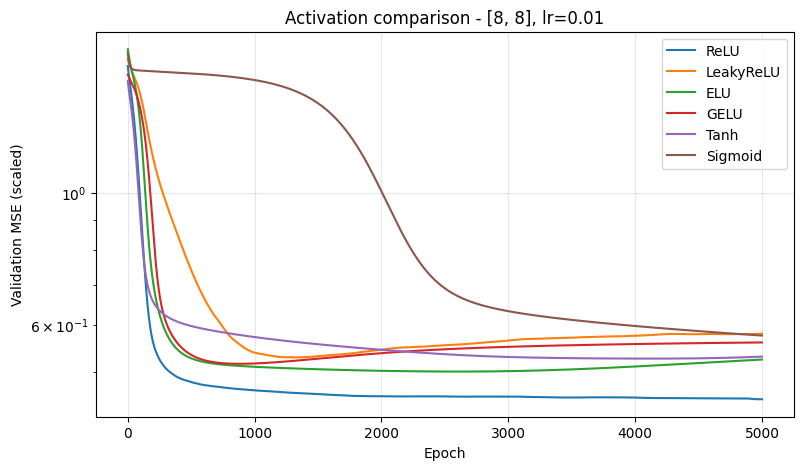

Best activation: ReLU


activation,mean R2,std R2,final val loss
ReLU,0.7124,0.0000,0.4492
ELU,0.6646,0.0000,0.5239
Tanh,0.6608,0.0000,0.5298
GELU,0.6417,0.0000,0.5598
Sigmoid,0.6320,0.0000,0.5748
LeakyReLU,0.6293,0.0000,0.5791


In [118]:
#Problem 1 Neural Network Training - Activation Functions
#first run
# n_in = Xs_train.shape[1] #neurons input
# hidden = 8 #neurons output to input 2nd

# seq_model = nn.Sequential(
#     nn.Linear(n_in, hidden),
#     nn.ReLU(),
#     nn.Linear(hidden, 1)
# )
# optimizer = torch.optim.SGD(seq_model.parameters(), lr=1e-2)
# training_loop(
#     n_epochs = 5000,
#     optimizer = optimizer,
#     model = seq_model,
#     loss_fn = nn.MSELoss(),
#     t_u_train = Xs_train,
#     t_u_val = Xs_val,
#     t_c_train = ys_train,
#     t_c_val = ys_val
# )

activations = {
    "ReLU":      nn.ReLU,
    "LeakyReLU": nn.LeakyReLU,
    "ELU":       nn.ELU,
    "GELU":      nn.GELU,
    "Tanh":      nn.Tanh,
    "Sigmoid":   nn.Sigmoid,
}
hidden = [8, 8] # 2 layers of 8
lr = .01
epochs = 5000

act_results = []
fig, ax = plt.subplots(figsize=(9, 5))

for name, act in activations.items():
    r2s, val_curves = [], []
    model = make_model(Xs_train.shape[1], hidden, act)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    h = training_loop(epochs, opt, model, nn.MSELoss(), Xs_train, Xs_val, ys_train, ys_val, textOut=False)
    val_curves.append(h["val_loss"])
    r2s.append(report_metrics(model, Xs_val, hy_v, scaler_y, textOut=False)["R2"])
    ax.plot(np.mean(val_curves, axis=0), label=name)
    act_results.append({"activation": name, "mean R2": np.mean(r2s), "std R2": np.std(r2s),
                        "final val loss": np.mean([c[-1] for c in val_curves])})

ax.set_xlabel("Epoch"); ax.set_ylabel("Validation MSE (scaled)")
ax.set_title(f"Activation comparison - {hidden}, lr={lr}")
ax.set_yscale("log"); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

act_df = pd.DataFrame(act_results).sort_values("mean R2", ascending=False)
best_name = act_df.iloc[0]["activation"]
BEST_ACT = activations[best_name]
print(f"Best activation: {best_name}")
display(act_df.style.format({"mean R2": "{:.4f}", "std R2": "{:.4f}", "final val loss": "{:.4f}"}).hide(axis="index"))


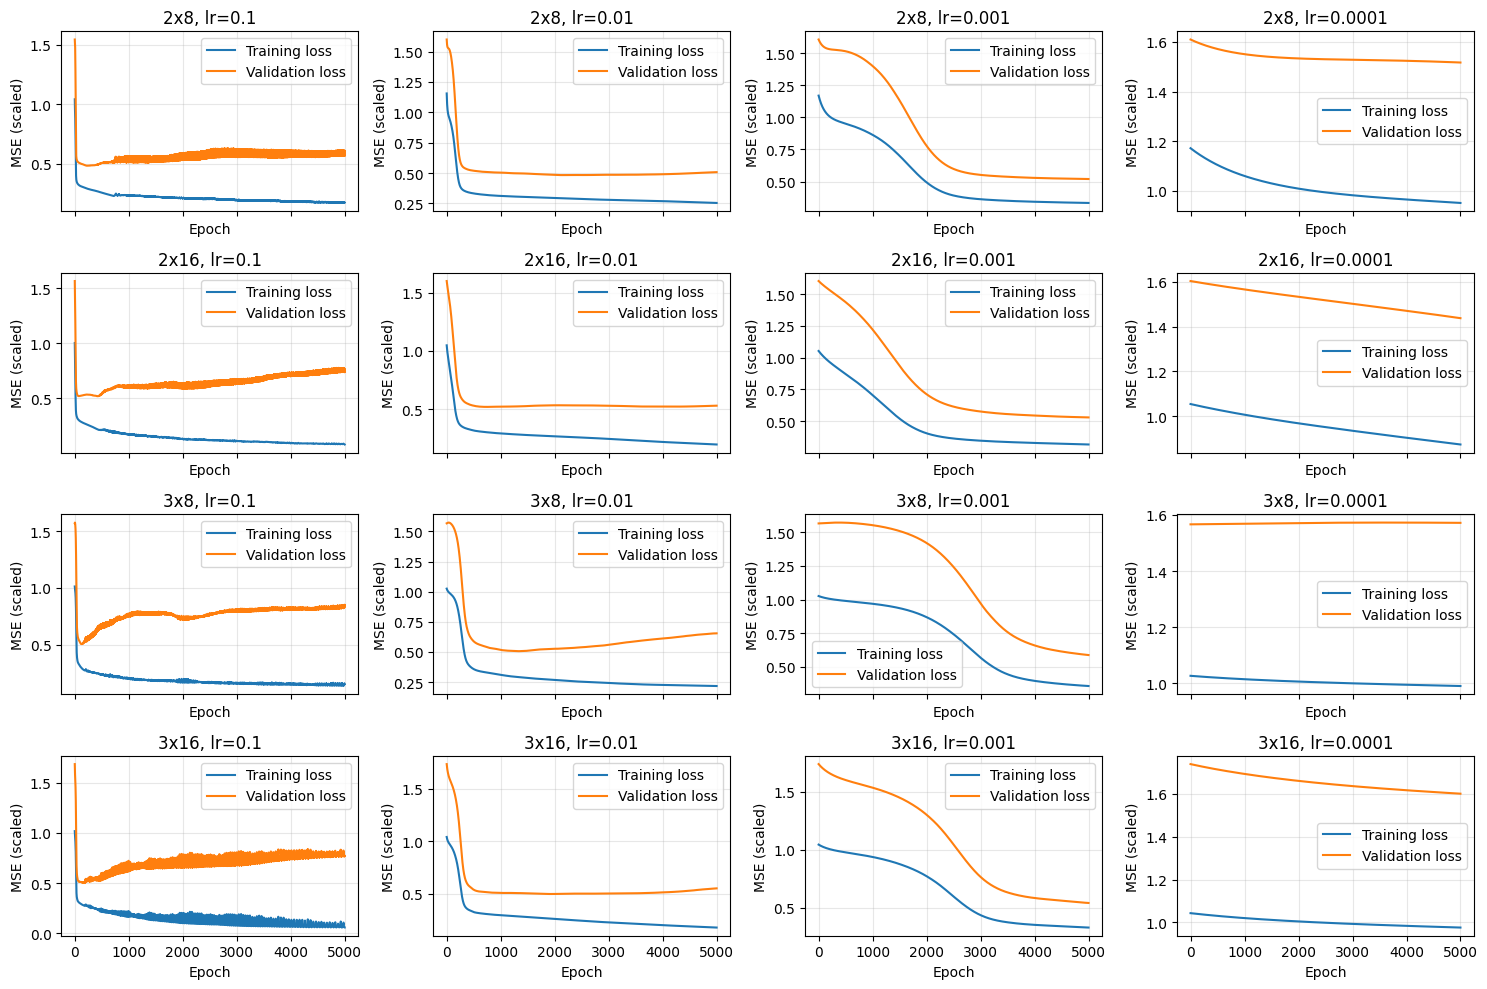

,model,lr,MSE,RMSE,R2
1,2x8,0.0100,1.584425e+12,1.258740e+06,0.674976
2,2x8,0.0010,1.620818e+12,1.273114e+06,0.667510
6,2x16,0.0010,1.654575e+12,1.286303e+06,0.660585
5,2x16,0.0100,1.654650e+12,1.286332e+06,0.660570
14,3x16,0.0010,1.684408e+12,1.297848e+06,0.654466
13,3x16,0.0100,1.724868e+12,1.313342e+06,0.646166
0,2x8,0.1000,1.774199e+12,1.331990e+06,0.636046
10,3x8,0.0010,1.834687e+12,1.354506e+06,0.623638
9,3x8,0.0100,2.041980e+12,1.428979e+06,0.581114
4,2x16,0.1000,2.305833e+12,1.518497e+06,0.526988


In [119]:
#Problem 1 Neural Network Training - Learning Rate & Configurations

learning_rates = [0.1, 0.01, 0.001, 0.0001]
activation = nn.ReLU
# Hidden Layers x Neurons per Layer
architectures = {
    "2x8":  [8, 8],
    "2x16":  [16, 16],
    "3x8":  [8, 8, 8],
    "3x16":  [16, 16, 16],
}

results = []
fig, axes = plt.subplots(len(architectures), len(learning_rates),
                         figsize=(15, 10), sharex=True)

for i, (arch_name, hid) in enumerate(architectures.items()):
    for j, lr in enumerate(learning_rates):
        torch.manual_seed(163)  # same init per run so comparisons are consistent
        model = make_model(Xs_train.shape[1], hid, activation)
        opt = torch.optim.SGD(model.parameters(), lr=lr)
        h = training_loop(5000, opt, model, nn.MSELoss(), Xs_train, Xs_val, ys_train, ys_val, textOut=False)
        plot_losses(h["train_loss"], h["val_loss"], title=f"{arch_name}, lr={lr}", ax=axes[i, j])
        m = report_metrics(model, Xs_val, hy_v, scaler_y, textOut=False)
        results.append({"model": arch_name, "lr": lr, **m})

plt.tight_layout()
plt.show()


results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
results_df


Sequential(
  (0): Linear(in_features=11, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)
Parameters: 177
Epoch 1, Training loss 1.1557, Validation loss 1.5997
Epoch 1000, Training loss 0.3121, Validation loss 0.5041
Epoch 2000, Training loss 0.2942, Validation loss 0.4853
Epoch 3000, Training loss 0.2799, Validation loss 0.4862
Epoch 4000, Training loss 0.2691, Validation loss 0.4905
Epoch 5000, Training loss 0.2544, Validation loss 0.5078


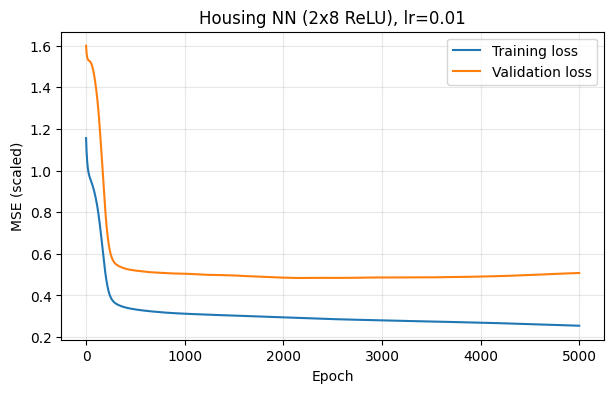

Training  : MSE = 793,689,743,084 ($²) | RMSE = $890,893 | R² = 0.7456
Validation: MSE = 1,584,425,326,526 ($²) | RMSE = $1,258,740 | R² = 0.6750
Linear Regression: MSE = 1,617,460,609,324 ($²) | RMSE = $1,271,794 | R² = 0.6682
SVR linear: RMSE = $1,313,418 | R² = 0.6461
SVR rbf   : RMSE = $1,393,637 | R² = 0.6016
SVR poly  : RMSE = $1,585,835 | R² = 0.4841
Best SVR kernel: linear


model,MSE,RMSE,R2
Neural Network (2x8 ReLU),"1,584,425,326,526 $²","$1,258,740",0.6750
Linear Regression (GD),"1,617,460,609,324 $²","$1,271,794",0.6682
SVR (linear),"1,725,067,051,245 $²","$1,313,418",0.6461


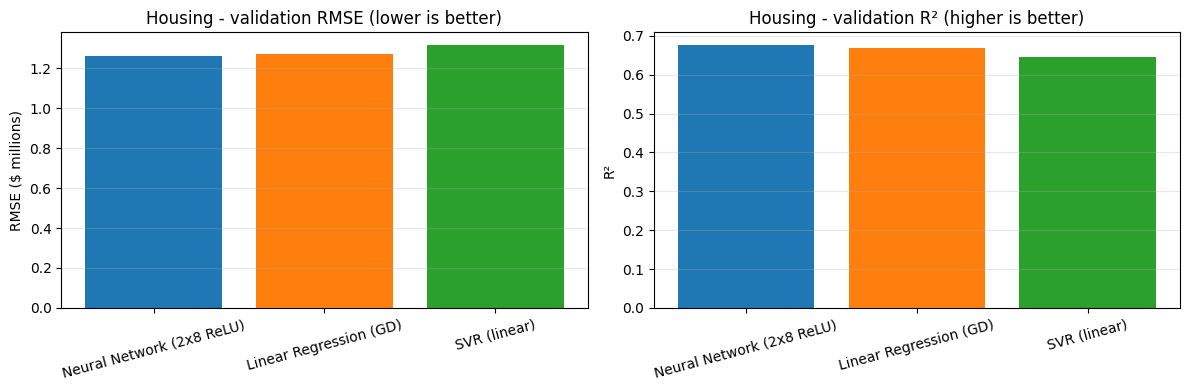

In [125]:
#Problem 1b - Model Comparisons to Gradient Descent & SVR

#final model selected from the tests above
best_act = nn.ReLU
best_lr = 0.01
FINAL_HIDDEN = architectures["2x8"]
FINAL_LR = best_lr
FINAL_EPOCHS = 5000
FINAL_BATCH = None   # full batch

torch.manual_seed(163)
nn_housing = make_model(Xs_train.shape[1], FINAL_HIDDEN, best_act)
print(nn_housing)
print("Parameters:", sum(p.numel() for p in nn_housing.parameters()))

opt = torch.optim.SGD(nn_housing.parameters(), lr=FINAL_LR)
hist_housing = training_loop(FINAL_EPOCHS, opt, nn_housing, nn.MSELoss(),
                             Xs_train, Xs_val, ys_train, ys_val, batch_size=FINAL_BATCH)

plot_losses(hist_housing["train_loss"], hist_housing["val_loss"],
            title=f"Housing NN (2x8 ReLU), lr={FINAL_LR:g}")
plt.show()

nn_train = report_metrics(nn_housing, Xs_train, hy_t, scaler_y, label="Training  ")
nn_val   = report_metrics(nn_housing, Xs_val, hy_v, scaler_y, label="Validation")


#from past homeworks
def gradient_descent(X_train, y_train, X_val, y_val, theta, alpha, iterations):
    m = len(y_train)
    train_cost_history = np.zeros(iterations)
    val_cost_history = np.zeros(iterations)
    for i in range(iterations):
        errors = X_train.dot(theta) - y_train
        theta = theta - (alpha / m) * X_train.T.dot(errors)
        train_cost_history[i] = np.sum((X_train.dot(theta) - y_train) ** 2) / (2 * len(y_train))
        val_cost_history[i] = np.sum((X_val.dot(theta) - y_val) ** 2) / (2 * len(y_val))
    return theta, train_cost_history, val_cost_history

# add bias column; train on standardized price so alpha=0.01 converges, then convert back to dollars
X_train_lr = np.hstack((np.ones((Xs_train_np.shape[0], 1)), Xs_train_np))
X_val_lr = np.hstack((np.ones((Xs_val_np.shape[0], 1)), Xs_val_np))

theta_lr, train_hist_lr, val_hist_lr = gradient_descent(X_train_lr, ys_train_np, X_val_lr, ys_val_np,
                                                        np.zeros(X_train_lr.shape[1]), 0.01, 5000)
lin_val = reg_scores(X_val_lr.dot(theta_lr), hy_v, scaler_y)
print(f"Linear Regression: MSE = {lin_val['MSE']:,.0f} ($²) | RMSE = ${lin_val['RMSE']:,.0f} | R² = {lin_val['R2']:.4f}")

#SVR
svr_results = {}
for k in ["linear", "rbf", "poly"]:
    svr = sklearn.svm.SVR(kernel=k, C=1.0, gamma="scale", degree=2).fit(Xs_train_np, ys_train_np)
    svr_results[k] = reg_scores(svr.predict(Xs_val_np), hy_v, scaler_y)
    print(f"SVR {k:6s}: RMSE = ${svr_results[k]['RMSE']:,.0f} | R² = {svr_results[k]['R2']:.4f}")

best_svr = max(svr_results, key=lambda k: svr_results[k]["R2"])
print("Best SVR kernel:", best_svr)


housing_cmp = pd.DataFrame([
    {"model": f"Neural Network (2x8 ReLU)", **nn_val},
    {"model": "Linear Regression (GD)", **lin_val},
    {"model": f"SVR ({best_svr})", **svr_results[best_svr]},
]).sort_values("R2", ascending=False)
display(housing_cmp.style.format({"MSE": "{:,.0f} $²", "RMSE": "${:,.0f}", "R2": "{:.4f}"}).hide(axis="index"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(housing_cmp["model"], housing_cmp["RMSE"] / 1e6, color=["C0", "C1", "C2"])
ax1.set_ylabel("RMSE ($ millions)"); ax1.set_title("Housing - validation RMSE (lower is better)")
ax2.bar(housing_cmp["model"], housing_cmp["R2"], color=["C0", "C1", "C2"])
ax2.set_ylabel("R²"); ax2.set_title("Housing - validation R² (higher is better)")
for a in (ax1, ax2):
    a.tick_params(axis="x", rotation=15); a.grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()


In [121]:
#Problem 2 data input
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Cancer.csv'
dc = pd.DataFrame(pd.read_csv(url))
dc = dc.drop(["id", "Unnamed: 32"], axis=1)
dc = dc[(dc != 0).all(axis=1)]

X = dc.drop(columns="diagnosis")
y = (dc["diagnosis"] == "M").astype(int).values   # 1 = malignant

# same split / standardization as HW3 and HW4
cx_t, cx_v, cy_t, cy_v = sklearn.model_selection.train_test_split(X, y, test_size=0.2, random_state=163)
scaler_c = sklearn.preprocessing.StandardScaler()
cx_t = scaler_c.fit_transform(cx_t)
cx_v = scaler_c.transform(cx_v)

Xc_train = torch.tensor(cx_t, dtype=torch.float32)
Xc_val   = torch.tensor(cx_v, dtype=torch.float32)
yc_train = torch.tensor(cy_t, dtype=torch.float32).unsqueeze(1)
yc_val   = torch.tensor(cy_v, dtype=torch.float32).unsqueeze(1)

print("Features:", X.shape[1], "| Training rows:", len(cy_t), "| Validation rows:", len(cy_v))

Features: 30 | Training rows: 444 | Validation rows: 112


In [122]:
#Problem 2 functions
def accuracy_fn(logits, y_true):
    return ((logits > 0).float() == y_true).float().mean().item()

def nn_predict(model, X):
    with torch.no_grad():
        return (model(X) > 0).int().numpy().ravel()

def plot_training(history, title):   # from HW3
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(history["train_loss"], label="Training loss")
    ax1.plot(history["val_loss"], label="Validation loss")
    ax1.set_title(title + ": Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Binary cross-entropy")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(history["train_acc"], label="Training accuracy")
    ax2.plot(history["val_acc"], label="Validation accuracy")
    ax2.set_title(title + ": Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
    ax2.set_ylim(0.6, 1.02); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def scores(y_true, y_pred):   # from HW4
    return {"Accuracy":  sklearn.metrics.accuracy_score(y_true, y_pred),
            "Precision": sklearn.metrics.precision_score(y_true, y_pred, zero_division=0),
            "Recall":    sklearn.metrics.recall_score(y_true, y_pred),
            "F1":        sklearn.metrics.f1_score(y_true, y_pred)}

def report_results(y_true, y_pred, title, class_names=("Benign", "Malignant")):   # from HW3
    s = scores(y_true, y_pred)
    print(title, "- validation results")
    for k, v in s.items():
        print(f"{k:9s}: {v:.4f}")
    matrix = sklearn.metrics.confusion_matrix(y_true, y_pred)
    sklearn.metrics.ConfusionMatrixDisplay(matrix, display_labels=list(class_names)).plot(cmap="Blues")
    plt.title("Confusion matrix: " + title); plt.show()
    return s

In [123]:
#Problem 2a - activation, architecture, and learning rate test
c_activations = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "ELU": nn.ELU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
c_architectures = {"2x8": [8, 8], "2x16": [16, 16], "3x16": [16, 16, 16], "32-16": [32, 16]}
c_learning_rates = [0.1, 0.01, 0.001]
c_epochs = 1000

c_results = []
for act_name, act in c_activations.items():
    for arch_name, hid in c_architectures.items():
        for lr in c_learning_rates:
            torch.manual_seed(163)
            model = make_model(Xc_train.shape[1], hid, act)
            opt = torch.optim.SGD(model.parameters(), lr=lr)
            h = training_loop(c_epochs, opt, model, nn.BCEWithLogitsLoss(),
                              Xc_train, Xc_val, yc_train, yc_val, acc_fn=accuracy_fn, textOut=False)
            s = scores(cy_v, nn_predict(model, Xc_val))
            c_results.append({"activation": act_name, "model": arch_name, "lr": lr,
                              "min val loss": min(h["val_loss"]), "final val loss": h["val_loss"][-1], **s})

c_results_df = pd.DataFrame(c_results).sort_values(["F1", "final val loss"], ascending=[False, True])
display(c_results_df.head(10).style.format({"lr": "{:g}", "min val loss": "{:.4f}", "final val loss": "{:.4f}",
        "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}).hide(axis="index"))

c_best = c_results_df.iloc[0]
print(f"Best: {c_best['model']}, {c_best['activation']}, lr={c_best['lr']:g}")

activation,model,lr,min val loss,final val loss,Accuracy,Precision,Recall,F1
ELU,3x16,0.01,0.0424,0.0424,1.0000,1.0000,1.0000,1.0000
Tanh,3x16,0.01,0.0441,0.0441,1.0000,1.0000,1.0000,1.0000
Sigmoid,2x16,0.1,0.0448,0.0448,1.0000,1.0000,1.0000,1.0000
Sigmoid,2x8,0.1,0.0521,0.0521,1.0000,1.0000,1.0000,1.0000
ELU,32-16,0.01,0.0537,0.0537,1.0000,1.0000,1.0000,1.0000
ELU,2x16,0.01,0.0538,0.0538,1.0000,1.0000,1.0000,1.0000
ELU,2x8,0.01,0.0568,0.0568,1.0000,1.0000,1.0000,1.0000
Tanh,2x16,0.01,0.0574,0.0574,1.0000,1.0000,1.0000,1.0000
Tanh,32-16,0.01,0.0581,0.0581,1.0000,1.0000,1.0000,1.0000
Tanh,2x8,0.01,0.0682,0.0682,1.0000,1.0000,1.0000,1.0000


Best: 3x16, ELU, lr=0.01


Sequential(
  (0): Linear(in_features=30, out_features=16, bias=True)
  (1): ELU(alpha=1.0)
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ELU(alpha=1.0)
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ELU(alpha=1.0)
  (6): Linear(in_features=16, out_features=1, bias=True)
)
Parameters: 1057
Epoch 1, Training loss 0.7560, Validation loss 0.7517
Epoch 1000, Training loss 0.0747, Validation loss 0.0424


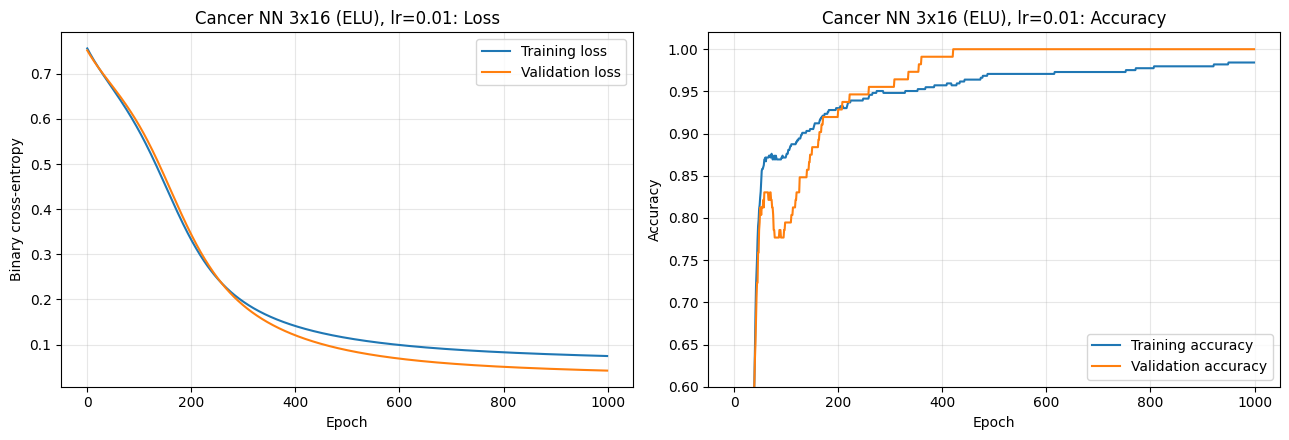

Cancer Neural Network - validation results
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1       : 1.0000


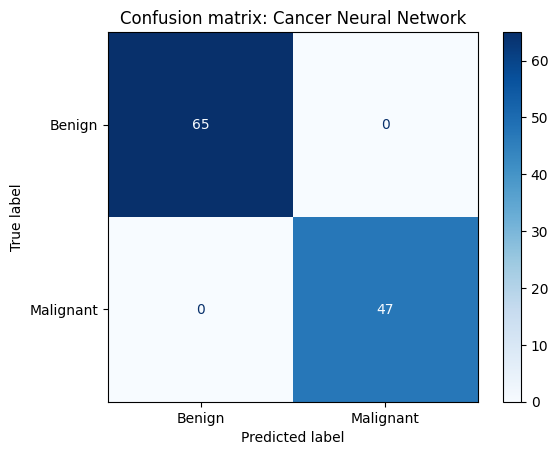

Cancer Logistic Regression - validation results
Accuracy : 0.9911
Precision: 1.0000
Recall   : 0.9787
F1       : 0.9892


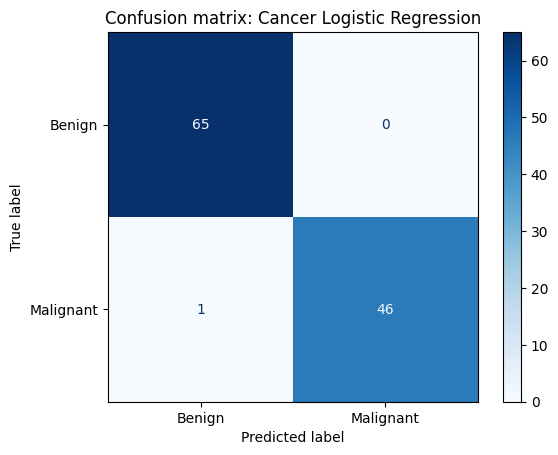

Cancer SVM (rbf) - validation results
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1       : 1.0000


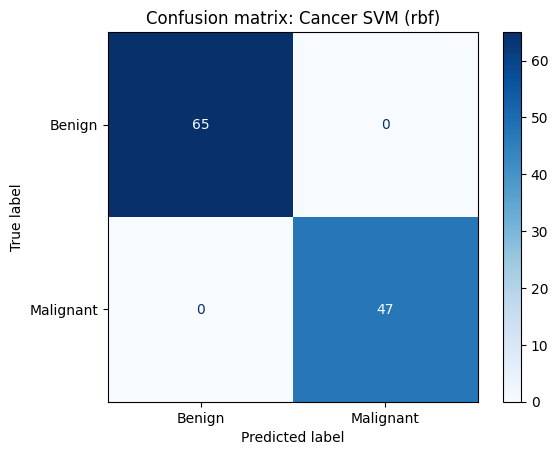

model,Accuracy,Precision,Recall,F1
"Neural Network (3x16, ELU)",1.0000,1.0000,1.0000,1.0000
Logistic Regression,0.9911,1.0000,0.9787,0.9892
SVM (rbf),1.0000,1.0000,1.0000,1.0000


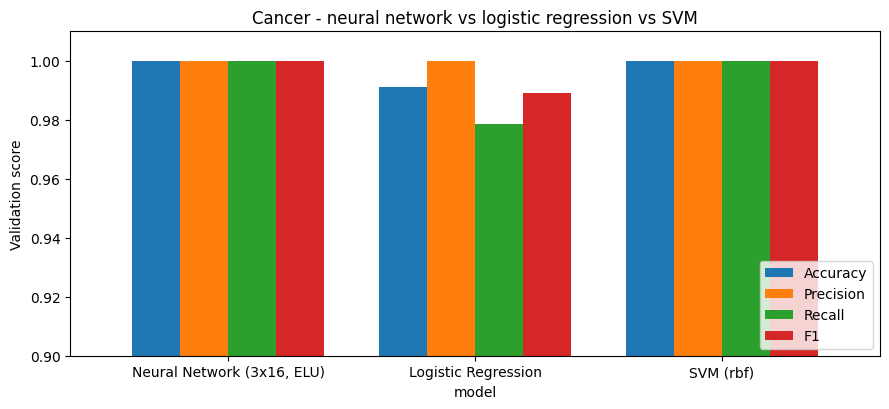

In [124]:
#Problem 2b - Model Comparisons to Gradient Descent & SVR

#neural network
C_HIDDEN = c_architectures[c_best["model"]]
C_ACT = c_activations[c_best["activation"]]
C_LR = c_best["lr"]
C_EPOCHS = c_epochs

torch.manual_seed(163)
nn_cancer = make_model(Xc_train.shape[1], C_HIDDEN, C_ACT)
print(nn_cancer)
print("Parameters:", sum(p.numel() for p in nn_cancer.parameters()))

opt = torch.optim.SGD(nn_cancer.parameters(), lr=C_LR)
hist_cancer = training_loop(C_EPOCHS, opt, nn_cancer, nn.BCEWithLogitsLoss(),
                            Xc_train, Xc_val, yc_train, yc_val, acc_fn=accuracy_fn)

plot_training(hist_cancer, f"Cancer NN {c_best['model']} ({c_best['activation']}), lr={C_LR:g}")
nn_c_scores = report_results(cy_v, nn_predict(nn_cancer, Xc_val), "Cancer Neural Network")

# logistic regression
logreg = sklearn.linear_model.SGDClassifier(loss="log_loss", penalty=None, learning_rate="constant",
                                            eta0=0.01, random_state=42)
for epoch in range(100):
    logreg.partial_fit(cx_t, cy_t, classes=[0, 1])
log_scores = report_results(cy_v, logreg.predict(cx_v), "Cancer Logistic Regression")

# SVM
svm_rbf = sklearn.svm.SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(cx_t, cy_t)
svm_scores = report_results(cy_v, svm_rbf.predict(cx_v), "Cancer SVM (rbf)")

#comparison
cancer_cmp = pd.DataFrame([
    {"model": f"Neural Network ({c_best['model']}, {c_best['activation']})", **nn_c_scores},
    {"model": "Logistic Regression", **log_scores},
    {"model": "SVM (rbf)", **svm_scores},
])
display(cancer_cmp.style.format({k: "{:.4f}" for k in ["Accuracy", "Precision", "Recall", "F1"]}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.2))
cancer_cmp.set_index("model")[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(ax=ax, rot=0, width=0.78)
ax.set_ylim(0.9, 1.01); ax.set_ylabel("Validation score")
ax.set_title("Cancer - neural network vs logistic regression vs SVM"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()